In [3]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier

In [4]:
train = pd.read_csv("../data/processed/train_engineered.csv")

train.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_38,DeviceType,DeviceInfo,HighValueFlag,LogTransactionAmt,AmountPercentile,HasEmail,HasDevice,IdentityInfoCount,AmountCategory
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,0,4.241327,0.499216,0,0,0,Medium
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,0,3.401197,0.122691,1,0,0,Low
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,0,4.094345,0.450009,1,0,0,Medium
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,0,3.931826,0.331933,1,0,0,Medium
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,T,mobile,SAMSUNG SM-G892A Build/NRD90M,0,3.931826,0.331933,1,1,21,Medium


In [5]:
y = train["isFraud"]

X = train.drop(columns=["isFraud"])

In [6]:
cat_cols = X.select_dtypes(include=["object"]).columns

for col in cat_cols:
    X[col] = X[col].astype(str)
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

In [7]:
imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [9]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [10]:
pred = rf.predict(X_test)

print("Accuracy :", accuracy_score(y_test,pred))
print("Precision:", precision_score(y_test,pred))
print("Recall   :", recall_score(y_test,pred))
print("F1 Score :", f1_score(y_test,pred))

Accuracy : 0.9798658854607647
Precision: 0.9502308876346844
Recall   : 0.4481006532784902
F1 Score : 0.6090101940151266


In [11]:
xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb.fit(X_train,y_train)

,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'
,feature_types,None


In [12]:
pred = xgb.predict(X_test)

print("Accuracy :", accuracy_score(y_test,pred))
print("Precision:", precision_score(y_test,pred))
print("Recall   :", recall_score(y_test,pred))
print("F1 Score :", f1_score(y_test,pred))

Accuracy : 0.9804416296948556
Precision: 0.9137539718565593
Recall   : 0.4870554076941689
F1 Score : 0.6354166666666666


In [13]:
import joblib

joblib.dump(xgb,"../saved_models/xgboost.pkl")
joblib.dump(imputer,"../saved_models/imputer.pkl")

print("Model Saved Successfully")

Model Saved Successfully


In [14]:
models = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, rf.predict(X_test)),
        accuracy_score(y_test, xgb.predict(X_test))
    ],
    "Precision": [
        precision_score(y_test, rf.predict(X_test)),
        precision_score(y_test, xgb.predict(X_test))
    ],
    "Recall": [
        recall_score(y_test, rf.predict(X_test)),
        recall_score(y_test, xgb.predict(X_test))
    ],
    "F1 Score": [
        f1_score(y_test, rf.predict(X_test)),
        f1_score(y_test, xgb.predict(X_test))
    ]
})

models

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.979866,0.950231,0.448101,0.609010
1,XGBoost,0.980442,0.913754,0.487055,0.635417


In [15]:
best_model = models.loc[models["F1 Score"].idxmax()]

print("="*50)
print("Best Model")
print("="*50)

print(best_model)

Best Model
Model         XGBoost
Accuracy     0.980442
Precision    0.913754
Recall       0.487055
F1 Score     0.635417
Name: 1, dtype: object


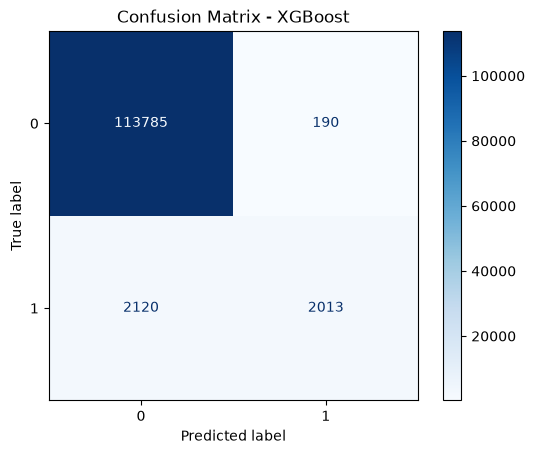

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    xgb,
    X_test,
    y_test,
    cmap="Blues"
)

plt.title("Confusion Matrix - XGBoost")
plt.show()

In [17]:
print(classification_report(y_test, xgb.predict(X_test)))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99    113975
           1       0.91      0.49      0.64      4133

    accuracy                           0.98    118108
   macro avg       0.95      0.74      0.81    118108
weighted avg       0.98      0.98      0.98    118108



In [18]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
311,V258,0.198955
254,V201,0.066250
202,V149,0.038208
123,V70,0.028742
144,V91,0.026244
386,V333,0.022774
347,V294,0.017657
29,C14,0.012385
27,C12,0.011938
278,V225,0.011727


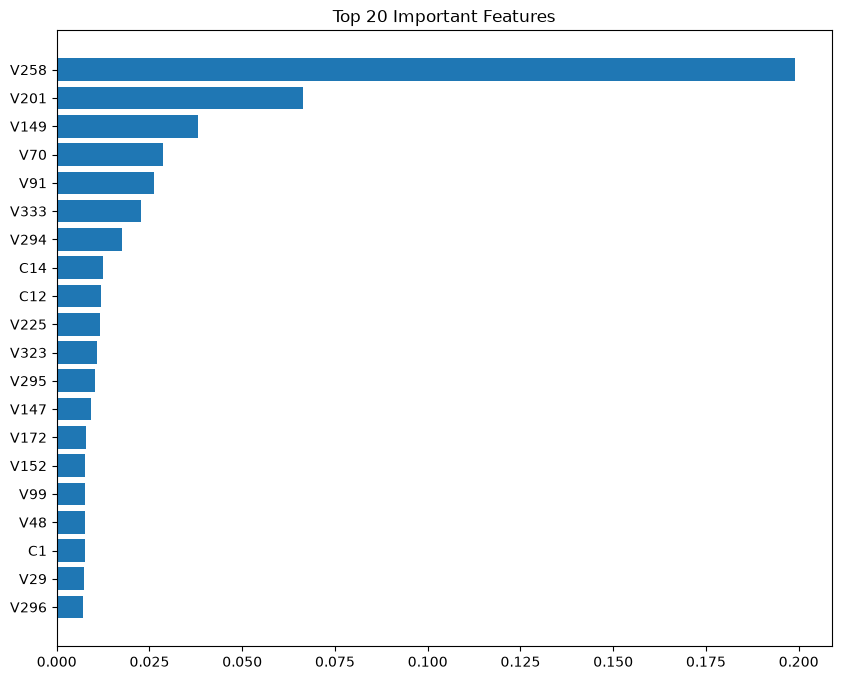

In [19]:
plt.figure(figsize=(10,8))

plt.barh(
    importance["Feature"][:20],
    importance["Importance"][:20]
)

plt.gca().invert_yaxis()

plt.title("Top 20 Important Features")

plt.show()

In [20]:
import joblib

joblib.dump(xgb, "../saved_models/xgboost.pkl")
joblib.dump(imputer, "../saved_models/imputer.pkl")

print("✅ Model Saved Successfully")

✅ Model Saved Successfully


# Model Training Summary

### Models Trained

- Random Forest
- XGBoost

### Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1 Score

### Selected Model

The model with the highest F1 Score was selected for deployment.

The trained model and preprocessing pipeline were saved for integration with the backend API.

In [21]:
type(xgb)

xgboost.sklearn.XGBClassifier